# 03 — Baseline 3D U-Net Training
**BraTS 2023 GLI Brain Tumor Segmentation | RCOEM 2026–27**

This notebook trains the **plain 3D U-Net** (no attention) as the baseline model.

Features:
- ✅ Auto-checkpointing every epoch (resume safely if DGX slot ends)
- ✅ Quick Test Mode — run on 10 patients first to verify setup
- ✅ TensorBoard logging
- ✅ Training curves plotted at the end

**Estimated training time on 1 DGX GPU:** ~8–10 hours (150 epochs, 500 patients)

## ⚙️ Configuration — Change This Before Running

In [1]:
import sys, os

# ─────────────────────────────────────────────────────────────
DATASET_PATH  = '/home/agrawalrb_1/Brain_Tumor_Segmentation/ASNR-MICCAI-BraTS2023-GLI-Challenge-TrainingData'  # ← CHANGE THIS
QUICK_TEST    = False   # True = 10 patients, 3 epochs — for verifying setup
RESUME        = True    # Auto-resume from latest checkpoint if available
FOLD          = 0       # Which K-Fold split to use (0, 1, or 2)
# ─────────────────────────────────────────────────────────────

PROJECT_ROOT = os.path.abspath('..')
if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)

from src.config import (
    BATCH_SIZE, NUM_EPOCHS, LEARNING_RATE, WEIGHT_DECAY,
    MAX_PATIENTS, N_FOLDS, DEVICE, RANDOM_SEED,
    EARLY_STOP_PATIENCE, LR_PATIENCE, LR_FACTOR
)
print(f'Device : {DEVICE}')
print(f'Config : batch={BATCH_SIZE}, epochs={NUM_EPOCHS}, lr={LEARNING_RATE}')

Device : cuda:0
Config : batch=4, epochs=100, lr=0.0001


In [2]:
import time
import numpy as np
import torch
import matplotlib.pyplot as plt
from torch.optim import Adam

from src.models   import UNet3D
from src.losses   import CombinedLoss
from src.dataset  import get_dataloaders
from src.utils    import (set_seed, save_checkpoint, load_checkpoint,
                          train_one_epoch, validate_one_epoch,
                          get_scheduler, get_writer, format_time)

set_seed(RANDOM_SEED)
print('✅ All imports OK')

✅ All imports OK


## 1️⃣ Load Data

In [3]:
train_loader, val_loader, test_loader, test_folders = get_dataloaders(
    dataset_path = DATASET_PATH,
    batch_size   = BATCH_SIZE,
    num_workers  = 4,
    fold         = FOLD,
    n_folds      = N_FOLDS,
    max_patients = MAX_PATIENTS,
    quick_test   = QUICK_TEST,
    quick_test_n = 10,
)
print(f'\nTrain batches: {len(train_loader)}')
print(f'Val batches  : {len(val_loader)}')

# Verify a batch
imgs, segs = next(iter(train_loader))
print(f'Image batch  : {imgs.shape}  ({imgs.dtype})')
print(f'Seg batch    : {segs.shape}  ({segs.dtype})')
print(f'Label values : {segs.unique().tolist()}')

Fold 0/3 (Subject-Grouped, 0 Leakage): Train=751 scans (680 subjects), Val=378 scans (340 subjects), Test=122 scans (113 subjects)
Dataset initialised: 751 patients (train+aug) — lazy loading enabled
Dataset initialised: 378 patients (val) — lazy loading enabled

Train batches: 376
Val batches  : 756


Image batch  : torch.Size([4, 4, 128, 128, 128])  (torch.float32)
Seg batch    : torch.Size([4, 128, 128, 128])  (torch.int64)


Label values : [0, 1, 2, 3]


## 2️⃣ Build Model, Optimiser, Loss

In [4]:
MODEL_NAME = 'baseline_unet3d'

model = UNet3D(in_channels=4, out_channels=4, init_features=32).to(DEVICE)

total_params = sum(p.numel() for p in model.parameters())
print(f'Model       : 3D U-Net (Baseline)')
print(f'Parameters  : {total_params:,}')

optimizer  = Adam(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
criterion  = CombinedLoss(num_classes=4, dice_weight=0.5, focal_weight=0.5)
scheduler  = get_scheduler(optimizer, patience=LR_PATIENCE, factor=LR_FACTOR)
writer     = get_writer(MODEL_NAME)

print(f'Optimizer   : Adam (lr={LEARNING_RATE}, wd={WEIGHT_DECAY})')
print(f'Loss        : CombinedLoss (Dice 50% + Focal 50%)')
print(f'Scheduler   : ReduceLROnPlateau (patience={LR_PATIENCE})')

Model       : 3D U-Net (Baseline)
Parameters  : 22,580,964


Optimizer   : Adam (lr=0.0001, wd=1e-05)
Loss        : CombinedLoss (Dice 50% + Focal 50%)
Scheduler   : ReduceLROnPlateau (patience=8)


## 3️⃣ Resume From Checkpoint (if available)

In [5]:
start_epoch = 0
best_val_dice = 0.0

if RESUME:
    start_epoch, best_val_dice = load_checkpoint(
        model, optimizer, model_name=MODEL_NAME, prefer_best=False
    )

max_epochs = 3 if QUICK_TEST else NUM_EPOCHS
print(f'\nTraining from epoch {start_epoch} → {max_epochs}')
print(f'Best val Dice so far: {best_val_dice:.4f}')

  No checkpoint found at ./checkpoints/baseline_unet3d_latest.pth — starting fresh.

Training from epoch 0 → 100
Best val Dice so far: 0.0000


## 4️⃣ Training Loop

In [6]:
train_losses, val_losses, val_dices = [], [], []
no_improve_count = 0
training_start = time.time()

for epoch in range(start_epoch, max_epochs):
    epoch_start = time.time()

    # ── Train ──────────────────────────────────────────────
    train_metrics = train_one_epoch(
        model, train_loader, optimizer, criterion, DEVICE, epoch, writer
    )

    # ── Validate ───────────────────────────────────────────
    val_metrics = validate_one_epoch(
        model, val_loader, criterion, DEVICE, epoch, writer
    )

    # ── LR Scheduler (monitor val WT Dice) ─────────────────
    scheduler.step(val_metrics['wt_dice'])

    # ── Checkpointing ──────────────────────────────────────
    is_best = val_metrics['wt_dice'] > best_val_dice
    if is_best:
        best_val_dice = val_metrics['wt_dice']
        no_improve_count = 0
    else:
        no_improve_count += 1

    save_checkpoint(model, optimizer, epoch, val_metrics['wt_dice'],
                    model_name=MODEL_NAME, is_best=is_best)

    # ── Logging ────────────────────────────────────────────
    train_losses.append(train_metrics['loss'])
    val_losses.append(val_metrics['loss'])
    val_dices.append(val_metrics['wt_dice'])

    epoch_time = time.time() - epoch_start
    total_elapsed = time.time() - training_start
    eta = epoch_time * (max_epochs - epoch - 1)

    print(f'Epoch [{epoch+1:3d}/{max_epochs}] '
          f'| Train Loss: {train_metrics["loss"]:.4f} '
          f'| Val Loss: {val_metrics["loss"]:.4f} '
          f'| Val WT Dice: {val_metrics["wt_dice"]:.4f} '
          f'| Best: {best_val_dice:.4f} '
          f'| ETA: {format_time(eta)}')

    # ── Early Stopping ─────────────────────────────────────
    if no_improve_count >= EARLY_STOP_PATIENCE:
        print(f'\n⚠️  Early stopping at epoch {epoch+1} (no improvement for {EARLY_STOP_PATIENCE} epochs)')
        break

writer.close()
print(f'\n🏁 Training complete!')
print(f'   Best Val WT Dice : {best_val_dice:.4f}')
print(f'   Total time       : {format_time(time.time() - training_start)}')

Epoch 0 [Train]:   0%|          | 0/376 [00:00<?, ?it/s]

/home/agrawalrb_1/Brain_Tumor_Segmentation/src/utils.py:133: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(dtype=torch.bfloat16):


Epoch 0 [Train]:   0%|          | 0/376 [00:04<?, ?it/s, loss=2.5867]

Epoch 0 [Train]:   0%|          | 1/376 [00:04<29:51,  4.78s/it, loss=2.5867]

Epoch 0 [Train]:   0%|          | 1/376 [00:05<29:51,  4.78s/it, loss=2.6757]

...

Epoch 67 [Val]:  99%|█████████▉| 750/756 [02:09<00:01,  5.50it/s]

Epoch 67 [Val]:  99%|█████████▉| 752/756 [02:10<00:00,  4.91it/s]

Epoch 67 [Val]: 100%|█████████▉| 754/756 [02:10<00:00,  6.21it/s]

Epoch 67 [Val]: 100%|██████████| 756/756 [02:11<00:00,  5.41it/s]

Epoch [ 68/100] | Train Loss: 0.0622 | Val Loss: 0.1185 | Val WT Dice: 0.9176 | Best: 0.9287 | ETA: 03h 45m 40s

⚠️  Early stopping at epoch 68 (no improvement for 20 epochs)

🏁 Training complete!
   Best Val WT Dice : 0.9287
   Total time       : 08h 08m 23s


## 5️⃣ Plot Training Curves

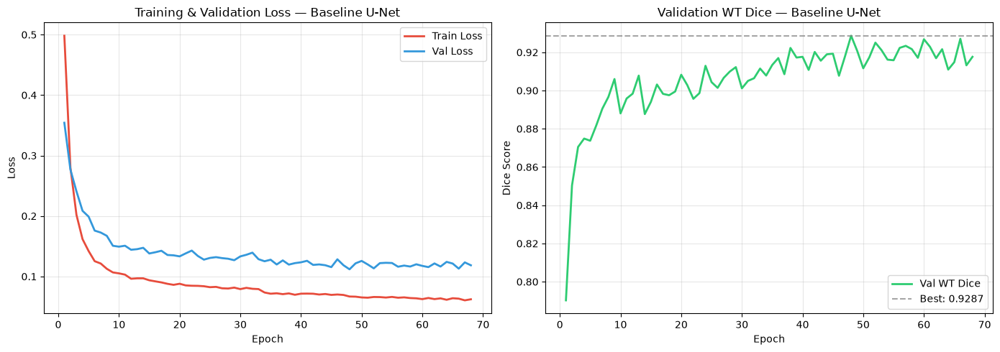

Saved: training_curves_baseline.png

🏁 Notebook 03 complete. Proceed to 04_train_attention_unet.ipynb


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
epochs_ran = range(1, len(train_losses) + 1)

axes[0].plot(epochs_ran, train_losses, label='Train Loss', color='#e74c3c', linewidth=2)
axes[0].plot(epochs_ran, val_losses,   label='Val Loss',   color='#3498db', linewidth=2)
axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Loss')
axes[0].set_title('Training & Validation Loss — Baseline U-Net')
axes[0].legend(); axes[0].grid(True, alpha=0.3)

axes[1].plot(epochs_ran, val_dices, label='Val WT Dice', color='#2ecc71', linewidth=2)
axes[1].axhline(y=max(val_dices), color='gray', linestyle='--', alpha=0.7,
                label=f'Best: {max(val_dices):.4f}')
axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('Dice Score')
axes[1].set_title('Validation WT Dice — Baseline U-Net')
axes[1].legend(); axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('training_curves_baseline.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: training_curves_baseline.png')
print('\n🏁 Notebook 03 complete. Proceed to 04_train_attention_unet.ipynb')